In [1]:
# Electricity Consumption Prediction

In [2]:
# Step 1: Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [4]:
# Step 2: Load dataset

In [5]:
df = pd.read_csv("energy_regression_dataset.csv")

df.head()

,temperature,humidity,appliances,energy_usage
0,35.733322,40.472388,15,174.469776
1,32.968205,75.408205,4,132.435368
2,37.227099,28.223387,18,182.695242
3,20.538683,55.947684,12,129.491119
4,14.851723,83.264081,16,138.003259


In [6]:
# Step 3: Explore the dataset

In [7]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (10000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   temperature   10000 non-null  float64
 1   humidity      10000 non-null  float64
 2   appliances    10000 non-null  int64  
 3   energy_usage  10000 non-null  float64
dtypes: float64(3), int64(1)
memory usage: 312.6 KB

Statistical Summary:
        temperature      humidity    appliances  energy_usage
count  10000.000000  10000.000000  10000.000000  10000.000000
mean      27.546432     54.955081      9.964700    132.385440
std       10.096148     20.167834      3.172895     29.299048
min       10.002778     20.007518      0.000000     32.461446
25%       18.836221     37.706143      8.000000    111.434941
50%       27.387380     54.855562     10.000000    132.427768
75%       36.302188     72.455772     12.000000    152.684633
max       44.9987

In [8]:
# Step 4: Exploratory Data Analysis (EDA)

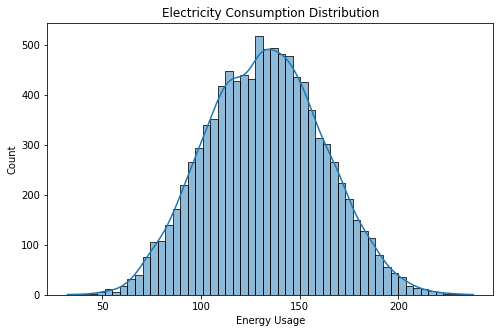

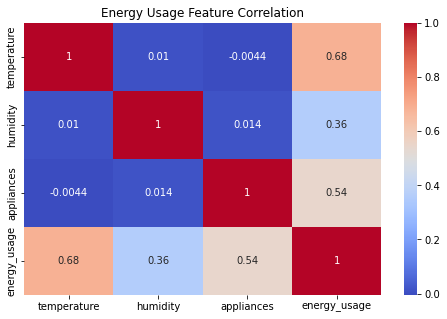

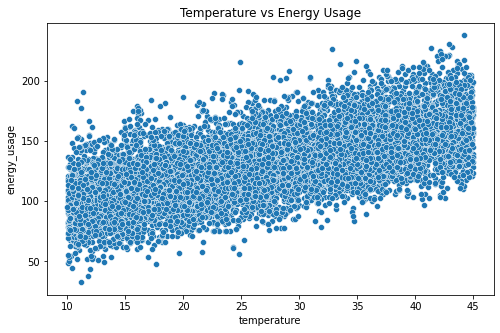

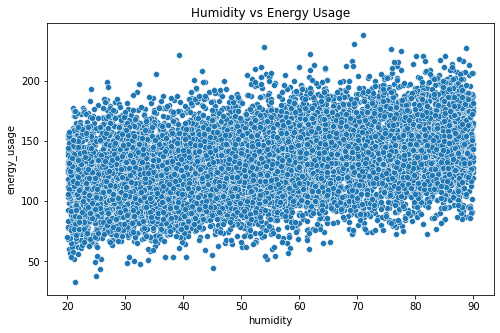

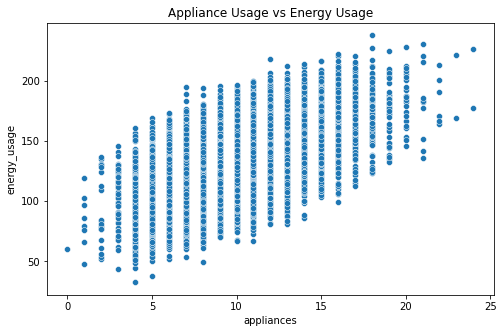

In [9]:
# Energy usage distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["energy_usage"], kde=True)
plt.title("Electricity Consumption Distribution")
plt.xlabel("Energy Usage")
plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Energy Usage Feature Correlation")
plt.show()

# Temperature vs Energy Usage
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="temperature", y="energy_usage")
plt.title("Temperature vs Energy Usage")
plt.show()

# Humidity vs Energy Usage
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="humidity", y="energy_usage")
plt.title("Humidity vs Energy Usage")
plt.show()

# Appliances vs Energy Usage
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="appliances", y="energy_usage")
plt.title("Appliance Usage vs Energy Usage")
plt.show()

In [10]:
# Step 5: Define independent and dependent variables

In [11]:
X = df[["temperature", "humidity", "appliances"]]

y = df["energy_usage"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   temperature   humidity  appliances
0    35.733322  40.472388          15
1    32.968205  75.408205           4
2    37.227099  28.223387          18
3    20.538683  55.947684          12
4    14.851723  83.264081          16

Target:
0    174.469776
1    132.435368
2    182.695242
3    129.491119
4    138.003259
Name: energy_usage, dtype: float64


In [12]:
# Step 6: Split the dataset

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 3)
Testing Data: (2000, 3)


In [14]:
# Step 7: Build and train the Linear Regression model

In [15]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [16]:
# Step 8: Make predictions

In [17]:
y_pred = model.predict(X_test)

print("Actual Energy Usage:")
print(y_test.head(10).values)

print("\nPredicted Energy Usage:")
print(y_pred[:10])

Actual Energy Usage:
[166.17051785 148.21357808 133.11428285 179.19477972 141.88795413
 180.54444922 165.32023827 160.84421554 155.95613515 105.07275174]

Predicted Energy Usage:
[169.40940749 139.54150536 117.00080213 174.20502205 144.04118455
 181.86843522 173.07672141 148.16961709 148.92316834 111.44235008]


In [18]:
# Step 9: Evaluate the model

In [19]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
-------------------------
MAE: 7.884020988273398
MSE: 99.44577649254511
RMSE: 9.972250322396901
R2 Score: 0.8872572169877286


In [20]:
# Step 10: Visualize actual vs predicted consumption

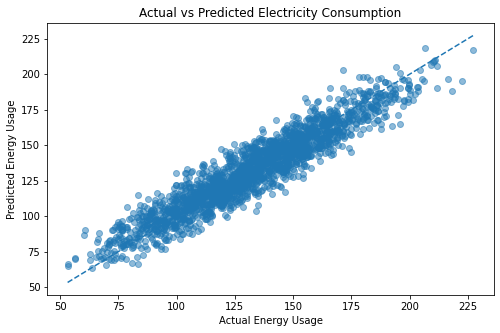

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Energy Usage")
plt.ylabel("Predicted Energy Usage")
plt.title("Actual vs Predicted Electricity Consumption")

plt.show()

In [22]:
# Step 11: Predict electricity consumption for a new scenario

In [23]:
new_data = pd.DataFrame({
    "temperature": [35],
    "humidity": [60],
    "appliances": [15]
})

predicted_usage = model.predict(new_data)

print(
    "Predicted Energy Usage:",
    round(predicted_usage[0], 2)
)

Predicted Energy Usage: 174.82


In [24]:
# Step 12: Display feature coefficients

In [25]:
regressor = model.named_steps["regressor"]

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": regressor.coef_
})

print(coefficients)

print("Intercept:", regressor.intercept_)

       Feature  Coefficient
0  temperature    20.037622
1     humidity    10.088897
2   appliances    15.763148
Intercept: 132.41063345202417
